<a href="https://colab.research.google.com/github/ShrinidhiUshetty/algorithmic-pricing-analysis/blob/main/notebooks/01_data_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Algorithmic Pricing Analysis Project")
print("Libraries imported successfully!")


Algorithmic Pricing Analysis Project
Libraries imported successfully!


In [29]:

import pandas as pd

# Load the Amazon Sales dataset
df = pd.read_csv('/content/amazon_sales.csv')

# Display the first 5 rows
df.head()


,OrderID,OrderDate,CustomerID,CustomerName,ProductID,ProductName,Category,Brand,Quantity,UnitPrice,Discount,Tax,ShippingCost,TotalAmount,PaymentMethod,OrderStatus,City,State,Country,SellerID
0,ORD0000001,2023-01-31,CUST001504,Vihaan Sharma,P00014,Drone Mini,Books,BrightLux,3,106.59,0.00,0.00,0.09,319.86,Debit Card,Delivered,Washington,DC,India,SELL01967
1,ORD0000002,2023-12-30,CUST000178,Pooja Kumar,P00040,Microphone,Home & Kitchen,UrbanStyle,1,251.37,0.05,19.10,1.74,259.64,Amazon Pay,Delivered,Fort Worth,TX,United States,SELL01298
2,ORD0000003,2022-05-10,CUST047516,Sneha Singh,P00044,Power Bank 20000mAh,Clothing,UrbanStyle,3,35.03,0.10,7.57,5.91,108.06,Debit Card,Delivered,Austin,TX,United States,SELL00908
3,ORD0000004,2023-07-18,CUST030059,Vihaan Reddy,P00041,Webcam Full HD,Home & Kitchen,Zenith,5,33.58,0.15,11.42,5.53,159.66,Cash on Delivery,Delivered,Charlotte,NC,India,SELL01164
4,ORD0000005,2023-02-04,CUST048677,Aditya Kapoor,P00029,T-Shirt,Clothing,KiddoFun,2,515.64,0.25,38.67,9.23,821.36,Credit Card,Cancelled,San Antonio,TX,Canada,SELL01411


In [2]:

# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()


Dataset Shape: (100000, 20)

Column Names:
['OrderID', 'OrderDate', 'CustomerID', 'CustomerName', 'ProductID', 'ProductName', 'Category', 'Brand', 'Quantity', 'UnitPrice', 'Discount', 'Tax', 'ShippingCost', 'TotalAmount', 'PaymentMethod', 'OrderStatus', 'City', 'State', 'Country', 'SellerID']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   OrderID        100000 non-null  object 
 1   OrderDate      100000 non-null  object 
 2   CustomerID     100000 non-null  object 
 3   CustomerName   100000 non-null  object 
 4   ProductID      100000 non-null  object 
 5   ProductName    100000 non-null  object 
 6   Category       100000 non-null  object 
 7   Brand          100000 non-null  object 
 8   Quantity       100000 non-null  int64  
 9   UnitPrice      100000 non-null  float64
 10  Discount       100000 non-nul

In [3]:

# Check duplicate rows
duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

# Check duplicate Order IDs
duplicate_orders = df["OrderID"].duplicated().sum()

print("Duplicate Order IDs:", duplicate_orders)


Total Duplicate Rows: 0
Duplicate Order IDs: 0


In [5]:

# Check invalid values

print("Zero or Negative Quantity:",
      (df["Quantity"] <= 0).sum())

print("Zero or Negative Unit Price:",
      (df["UnitPrice"] <= 0).sum())

print("Negative Total Amount:",
      (df["TotalAmount"] < 0).sum())

print("Negative Discount:",
      (df["Discount"] < 0).sum())

# Check discount range
print("Minimum Discount:", df["Discount"].min())
print("Maximum Discount:", df["Discount"].max())


Zero or Negative Quantity: 0
Zero or Negative Unit Price: 0
Negative Total Amount: 0
Negative Discount: 0
Minimum Discount: 0.0
Maximum Discount: 0.3


In [7]:

# Convert OrderDate into datetime format
df["OrderDate"] = pd.to_datetime(
    df["OrderDate"],
    errors="coerce"
)

# Check the updated data type
print("OrderDate Data Type:", df["OrderDate"].dtype)

# Check invalid dates
print("Invalid Dates:", df["OrderDate"].isnull().sum())

# Check date range
print("Earliest Date:", df["OrderDate"].min())
print("Latest Date:", df["OrderDate"].max())


OrderDate Data Type: datetime64[ns]
Invalid Dates: 0
Earliest Date: 2020-01-01 00:00:00
Latest Date: 2024-12-29 00:00:00


In [9]:

# Save the cleaned dataset
df.to_csv(
    "/content/amazon_sales_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])


Cleaned dataset saved successfully!
Total Rows: 100000
Total Columns: 20


In [9]:

# Count unique prices for each product
price_changes = df.groupby("ProductID")["UnitPrice"].nunique()

# Count products with more than one price
products_with_changes = (price_changes > 1).sum()

print("Total Unique Products:", df["ProductID"].nunique())

print("Products with Multiple Prices:", products_with_changes)

# Display the first 10 products and their unique price counts
print("\nPrice Variations by Product:")
print(price_changes.head(10))


Total Unique Products: 50
Products with Multiple Prices: 50

Price Variations by Product:
ProductID
P00001    1970
P00002    1882
P00003    1968
P00004    1926
P00005    1952
P00006    1969
P00007    2002
P00008    1981
P00009    1996
P00010    1957
Name: UnitPrice, dtype: int64


In [10]:

# Calculate monthly sales performance
monthly_sales = (
    df.groupby("YearMonth")
    .agg(
        TotalRevenue=("TotalAmount", "sum"),
        TotalQuantity=("Quantity", "sum"),
        AveragePrice=("UnitPrice", "mean"),
        TotalOrders=("OrderID", "nunique")
    )
    .reset_index()
)

# Display the first 10 months
print(monthly_sales.head(10))


  YearMonth  TotalRevenue  TotalQuantity  AveragePrice  TotalOrders
0   2020-01    1637069.40           5225    307.125786         1730
1   2020-02    1339388.21           4343    307.335940         1490
2   2020-03    1587125.66           5050    311.191608         1685
3   2020-04    1588347.29           5156    303.121158         1692
4   2020-05    1533834.17           5061    299.554043         1672
5   2020-06    1500269.29           4883    303.475836         1633
6   2020-07    1552981.94           5061    304.691921         1687
7   2020-08    1640874.93           5439    300.192608         1783
8   2020-09    1554682.21           5023    304.631138         1679
9   2020-10    1515403.62           4908    304.125525         1647


In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load Amazon Sales Dataset
df = pd.read_csv("/content/amazon_sales.csv")

# Convert OrderDate to datetime
df["OrderDate"] = pd.to_datetime(df["OrderDate"])

# Create YearMonth column
df["YearMonth"] = df["OrderDate"].dt.to_period("M")

print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])


Dataset loaded successfully!
Total Rows: 100000


In [13]:

import os

print(os.listdir("/content"))


['.config', 'amazon_sales.csv', 'sample_data']


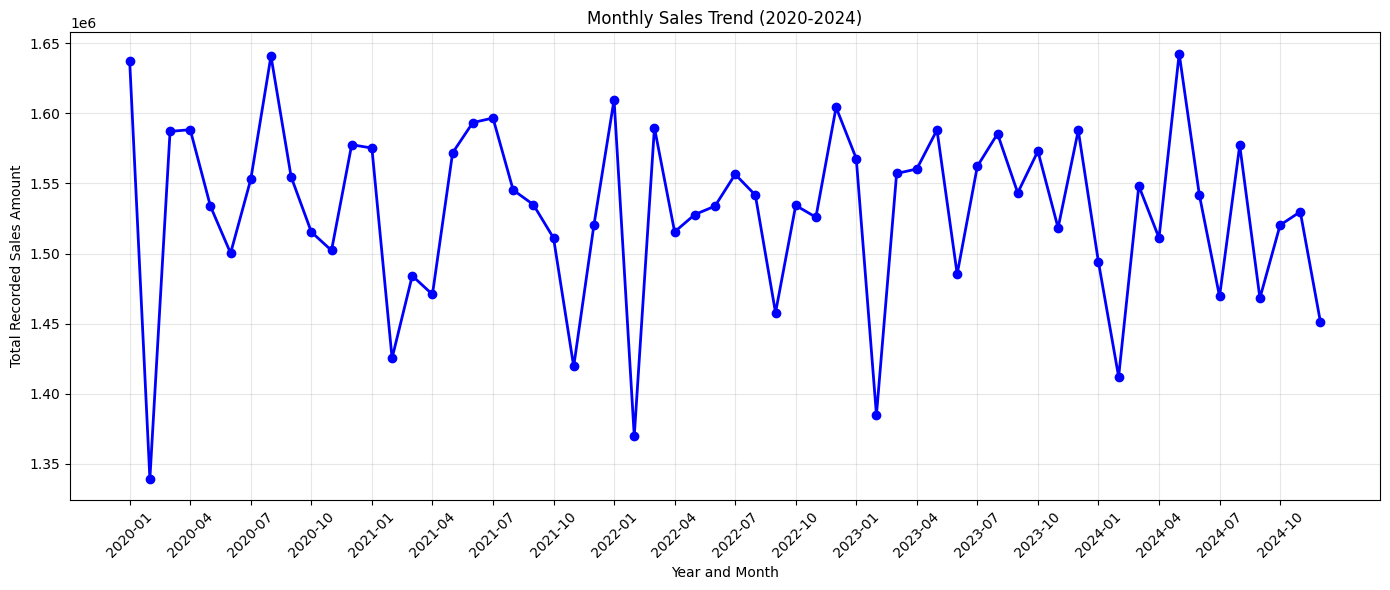

In [14]:

# Monthly revenue trend visualization
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["YearMonth"].astype(str),
    monthly_sales["TotalRevenue"],
    color="blue",
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend (2020-2024)")
plt.xlabel("Year and Month")
plt.ylabel("Total Recorded Sales Amount")

# Display every third month to avoid overlapping labels
plt.xticks(range(0, len(monthly_sales), 3), rotation=45)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


  ProductID  AveragePrice  TotalQuantity
0    P00001    300.832136           6008
1    P00002    310.940868           5782
2    P00003    307.154077           6060
3    P00004    303.000511           5811
4    P00005    304.344163           5992
5    P00006    303.370169           6170
6    P00007    306.598461           6161
7    P00008    298.182946           6111
8    P00009    300.172562           5996
9    P00010    312.787526           5983


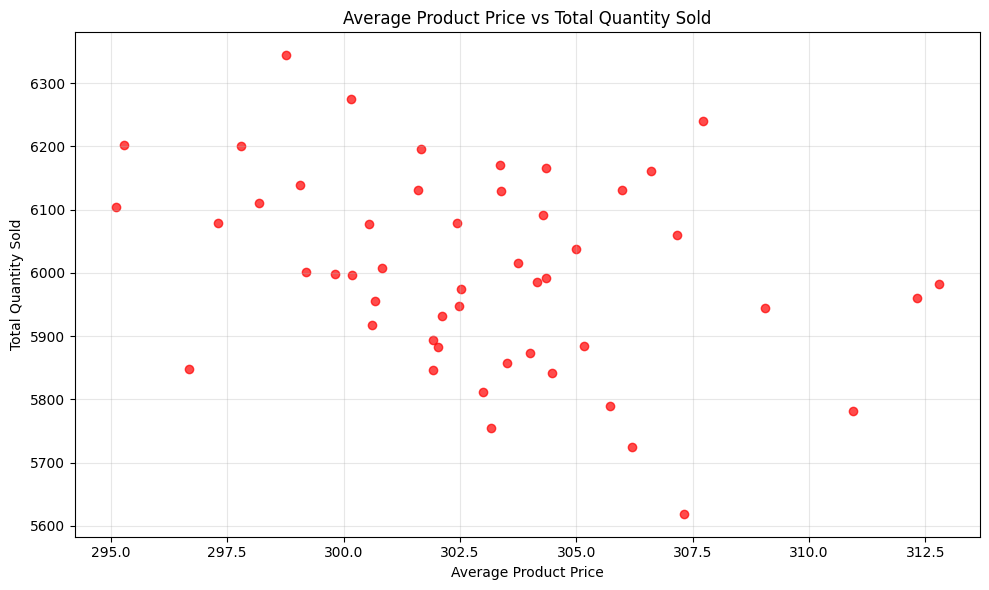

In [18]:

# Analyze average price and quantity by product
product_analysis = (
    df.groupby("ProductID")
    .agg(
        AveragePrice=("UnitPrice", "mean"),
        TotalQuantity=("Quantity", "sum")
    )
    .reset_index()
)

print(product_analysis.head(10))

# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    product_analysis["AveragePrice"],
    product_analysis["TotalQuantity"],
    color="red",
    alpha=0.7
)

plt.title("Average Product Price vs Total Quantity Sold")
plt.xlabel("Average Product Price")
plt.ylabel("Total Quantity Sold")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:

# Calculate correlation between price and quantity
correlation = product_analysis[
    ["AveragePrice", "TotalQuantity"]
].corr()

print(correlation)


               AveragePrice  TotalQuantity
AveragePrice        1.00000       -0.32925
TotalQuantity      -0.32925        1.00000


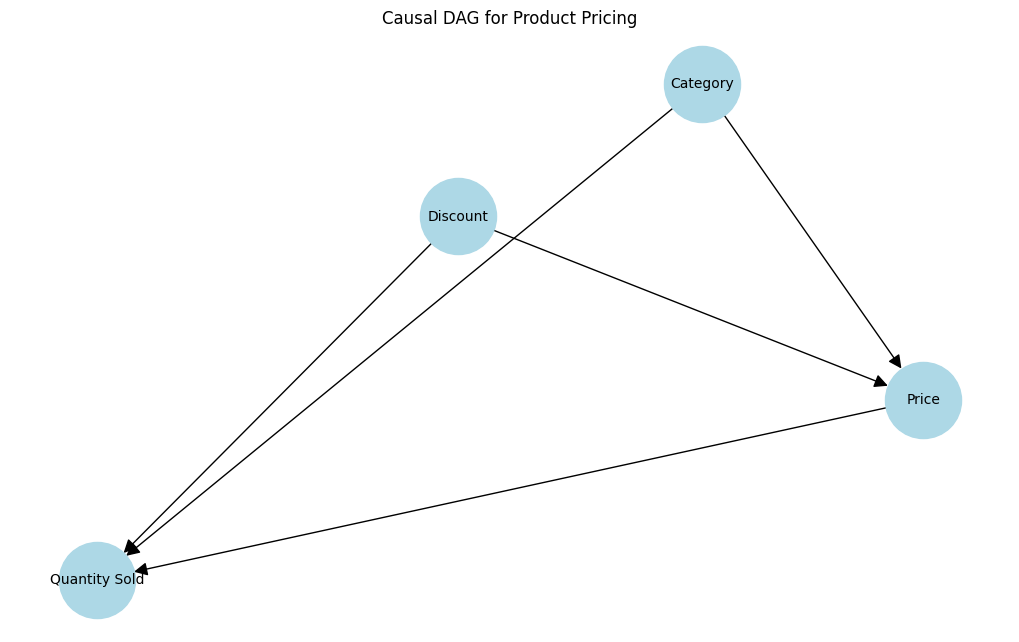

In [21]:

import networkx as nx
import matplotlib.pyplot as plt

# Create a directed graph
G = nx.DiGraph()

# Add assumed causal relationships
G.add_edges_from([
    ("Category", "Price"),
    ("Category", "Quantity Sold"),
    ("Discount", "Price"),
    ("Discount", "Quantity Sold"),
    ("Price", "Quantity Sold")
])

# Draw the graph
plt.figure(figsize=(10, 6))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G, pos,
    with_labels=True,
    node_color="lightblue",
    node_size=3000,
    font_size=10,
    arrows=True,
    arrowsize=20
)

plt.title("Causal DAG for Product Pricing")
plt.show()


In [23]:

# Examine pricing-related columns
print(
    df[
        ["UnitPrice", "Discount", "Quantity", "TotalAmount"]
    ].head(10)
)

# Check discount values
print("\nDiscount statistics:")
print(df["Discount"].describe())


   UnitPrice  Discount  Quantity  TotalAmount
0     106.59      0.00         3       319.86
1     251.37      0.05         1       259.64
2      35.03      0.10         3       108.06
3      33.58      0.15         5       159.66
4     515.64      0.25         2       821.36
5     449.73      0.00         4      2017.53
6     219.81      0.20         2       394.81
7     306.51      0.05         2       617.73
8     146.09      0.00         4       638.14
9     278.21      0.10         2       565.75

Discount statistics:
count    100000.000000
mean          0.074226
std           0.082583
min           0.000000
25%           0.000000
50%           0.050000
75%           0.100000
max           0.300000
Name: Discount, dtype: float64


In [24]:

# Calculate effective unit price after discount
df["EffectivePrice"] = (
    df["UnitPrice"] * (1 - df["Discount"])
)

# Display the first 10 rows
print(
    df[
        ["UnitPrice", "Discount", "EffectivePrice"]
    ].head(10)
)


   UnitPrice  Discount  EffectivePrice
0     106.59      0.00        106.5900
1     251.37      0.05        238.8015
2      35.03      0.10         31.5270
3      33.58      0.15         28.5430
4     515.64      0.25        386.7300
5     449.73      0.00        449.7300
6     219.81      0.20        175.8480
7     306.51      0.05        291.1845
8     146.09      0.00        146.0900
9     278.21      0.10        250.3890


In [25]:

# Analyze effective price variations by product
price_variation = (
    df.groupby("ProductID")
    .agg(
        MinPrice=("EffectivePrice", "min"),
        MaxPrice=("EffectivePrice", "max"),
        AveragePrice=("EffectivePrice", "mean"),
        TotalOrders=("OrderID", "nunique")
    )
    .reset_index()
)

# Calculate the difference between maximum and minimum price
price_variation["PriceRange"] = (
    price_variation["MaxPrice"] - price_variation["MinPrice"]
)

print(price_variation.head(10))



  ProductID  MinPrice  MaxPrice  AveragePrice  TotalOrders  PriceRange
0    P00001    4.5280    599.13    277.678012         2008    594.6020
1    P00002    4.2480    598.67    287.626010         1913    594.4220
2    P00003    5.0000    599.94    284.668045         1989    594.9400
3    P00004    4.2880    599.49    278.359763         1958    595.2020
4    P00005    5.2250    599.35    282.784573         1996    594.1250
5    P00006    4.1550    599.32    280.752136         2010    595.1650
6    P00007    3.9375    598.11    283.922517         2034    594.1725
7    P00008    3.8250    599.27    276.298348         2006    595.4450
8    P00009    4.6800    598.24    277.578858         2030    593.5600
9    P00010    4.7160    598.92    290.401349         1989    594.2040


In [26]:

# Check how many product names belong to each ProductID
product_check = (
    df.groupby("ProductID")["ProductName"]
    .nunique()
    .reset_index(name="UniqueProductNames")
)

print(product_check.head(10))

print(
    "Product IDs linked to multiple names:",
    (product_check["UniqueProductNames"] > 1).sum()
)


  ProductID  UniqueProductNames
0    P00001                   1
1    P00002                   1
2    P00003                   1
3    P00004                   1
4    P00005                   1
5    P00006                   1
6    P00007                   1
7    P00008                   1
8    P00009                   1
9    P00010                   1
Product IDs linked to multiple names: 0


In [27]:

# Select transactions for one product
product_history = df[
    df["ProductID"] == "P00001"
].copy()

# Sort transactions by date
product_history = product_history.sort_values("OrderDate")

# Display the first 15 transactions
print(
    product_history[
        ["OrderDate", "ProductName",
         "UnitPrice", "Discount",
         "EffectivePrice", "Quantity"]
    ].head(15)
)


       OrderDate       ProductName  UnitPrice  Discount  EffectivePrice  \
87705 2020-01-01  Wireless Earbuds     530.01      0.05        503.5095   
79506 2020-01-03  Wireless Earbuds     491.94      0.25        368.9550   
85465 2020-01-04  Wireless Earbuds      19.79      0.00         19.7900   
96144 2020-01-04  Wireless Earbuds     445.87      0.00        445.8700   
69853 2020-01-05  Wireless Earbuds     355.66      0.05        337.8770   
75680 2020-01-06  Wireless Earbuds     512.73      0.00        512.7300   
19583 2020-01-08  Wireless Earbuds     431.53      0.05        409.9535   
23751 2020-01-08  Wireless Earbuds     175.76      0.00        175.7600   
56230 2020-01-09  Wireless Earbuds     360.77      0.00        360.7700   
41333 2020-01-09  Wireless Earbuds     463.72      0.15        394.1620   
48172 2020-01-10  Wireless Earbuds     139.96      0.05        132.9620   
96037 2020-01-11  Wireless Earbuds     258.06      0.05        245.1570   
71635 2020-01-11  Wireles

In [28]:

# Correlation for Wireless Earbuds only
earbuds = df[df["ProductID"] == "P00001"]

correlation = earbuds[
    ["EffectivePrice", "Quantity"]
].corr()

print("Wireless Earbuds Price-Quantity Correlation:")
print(correlation)

print("\nTotal Transactions:", len(earbuds))


Wireless Earbuds Price-Quantity Correlation:
                EffectivePrice  Quantity
EffectivePrice        1.000000  0.030419
Quantity              0.030419  1.000000

Total Transactions: 2008
